# Benchmark : descente de gradient "colorimetrique" dans le plan complexe

Ce notebook evalue systematiquement la methode d'optimisation etudiee dans l'application :
une **descente de gradient dont le seul capteur est la couleur** d'un domain coloring
(teinte = `arg f(z)`, luminosite = bande de `log_10|f(z)|`).

**Plan du benchmark**
1. Encodage / decodage couleur (capteur simule, quantification en bits)
2. Fonctions tests analytiques (zeros connus)
3. Deux capteurs : lecture de pixels d'image vs couleur calculee a la demande
4. Descente "par couleurs" vs descente exacte (gradient numerique de `log|f|`)
5. T1-T6 : eps, pas alpha, profondeur de quantification, resolution d'image, cout, racines multiples
6. Tableau recapitulatif + bilan

**Utilisation** : `Execution -> Tout executer`. Numpy / pandas / matplotlib sont preinstalles sur Colab.
Duree totale : environ 2-3 minutes.


In [1]:
import time, math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb

RNG = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)


numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2


## 1. Le capteur couleur : encodage et decodage

Chaque valeur complexe `f(z)` est encodee comme dans un domain coloring :

- **teinte** (hue) = `arg f(z)` - *non utilisee par la descente, mais presente dans le capteur*
- **luminosite** (value) = `0.14 + 0.72 x frac(log_10|f(z)|)` - les bandes sombres marquent `|f| = 10^k`

Le capteur est **quantifie** : la couleur est arrondie sur `bits` bits par canal
(`bits = 8` ~ image RGB classique). Le decodage inverse la luminosite en
`t ~ log_10|f|`, avec **depliage de bande** : `t` et `t + 1` ont la meme couleur,
on choisit l'entier le plus proche d'une reference (l'ambiguite x10 s'annule
dans les differences qui forment le gradient).


In [2]:
L0, LAMP, SAT = 0.14, 0.72, 0.85   # plage de luminosite et saturation


def f_to_hsv(F):
    """Valeur(s) complexe(s) -> (h, s, v) : teinte = arg, luminosite = bande de log10|f|."""
    F = np.asarray(F, dtype=complex)
    mod = np.nan_to_num(np.abs(F), nan=0.0, posinf=1e300)
    ok = mod > 1e-290
    hue = (np.angle(F) / (2 * np.pi)) % 1.0
    band = np.where(ok, (np.log10(np.maximum(mod, 1e-300)) % 1.0 + 1.0) % 1.0, 0.0)
    val = np.where(ok, L0 + LAMP * band, 0.05)
    sat = np.where(ok, SAT, 0.0)
    return np.stack([hue, sat, val], axis=-1)


def color_of(F, bits=8):
    """Valeur complexe -> couleur RGB quantifiee (capteur a `bits` bits/canal), floats dans [0,1]."""
    rgb = hsv_to_rgb(np.clip(f_to_hsv(F), 0.0, 1.0))
    if bits >= 16:
        return rgb
    levels = 2 ** bits - 1
    return np.round(rgb * levels) / levels


def decode_t(rgb, ref_t=0.0):
    """Luminosite -> bande de log10|f|, depliee pres de ref_t (leve l'ambiguite x10^k)."""
    v = np.max(rgb, axis=-1)
    band = float(np.clip((v - L0) / LAMP, 0.0, 0.9999))
    return band + float(np.round(ref_t - band))


# -- auto-test : decode(color(x)) doit redonner log10|x| (erreur ~ quantification) --
for x in [0.03, 1.0, 7.5, 123.0, 4e-5]:
    lx = float(np.log10(x))
    t = decode_t(color_of(x * np.exp(0.5j), bits=8), ref_t=lx)
    print(f"|f| = {x:>10.4g} | log10|f| = {lx:+8.3f} | t decode = {t:+8.3f} | erreur = {abs(t - lx):.4f}")


|f| =       0.03 | log10|f| =   -1.523 | t decode =   -1.525 | erreur = 0.0016
|f| =          1 | log10|f| =   +0.000 | t decode =   +0.002 | erreur = 0.0016
|f| =        7.5 | log10|f| =   +0.875 | t decode =   +0.873 | erreur = 0.0020
|f| =        123 | log10|f| =   +2.090 | t decode =   +2.089 | erreur = 0.0011
|f| =      4e-05 | log10|f| =   -4.398 | t decode =   -4.399 | erreur = 0.0013


## 2. Fonctions tests

Six fonctions analytiques couvrant des situations croissantes de difficulte :

| nom | f(z) | difficulte |
|---|---|---|
| `quad` | (z - r_1)(z - r_2) | cas de base, 2 zeros simples |
| `cubic` | z^3 - 1 | 3 bassins symetriques |
| `expz` | e^z - z - 1 | zeros non triviaux, dynamique raide |
| `poly5` | polynome degre 5 a racines aleatoires | 5 bassins desequilibres |
| `double` | (z - 0.8i)^2(z + 1.3) | **racine double** |
| `sinz` | sin(z) - z | **racine triple en 0** |


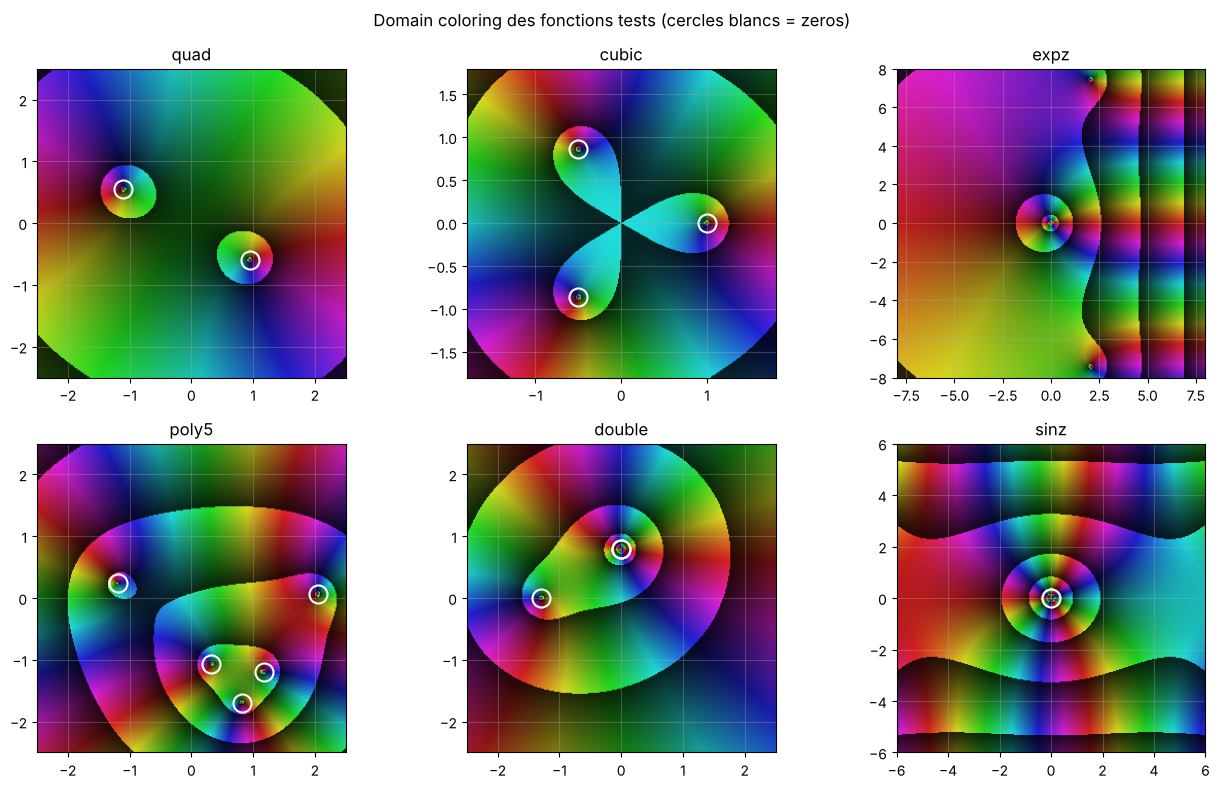

In [3]:
def make_poly(deg, seed=0):
    """Polynome a racines aleatoires de module dans [0.8, 2.2]."""
    rng = np.random.default_rng(seed)
    roots = rng.uniform(0.8, 2.2, deg) * np.exp(1j * rng.uniform(0, 2 * np.pi, deg))
    coeffs = np.poly(roots)
    return (lambda z: np.polyval(coeffs, z)), list(roots)


F_POLY5, Z_POLY5 = make_poly(5, seed=7)

TESTS = {
    "quad":   dict(f=lambda z: (z - (-1.1 + 0.55j)) * (z - (0.95 - 0.60j)),
                   zeros=[-1.1 + 0.55j, 0.95 - 0.60j],
                   xlim=(-2.5, 2.5), ylim=(-2.5, 2.5)),
    "cubic":  dict(f=lambda z: z**3 - 1,
                   zeros=[np.exp(2j * np.pi * k / 3) for k in range(3)],
                   xlim=(-1.8, 1.8), ylim=(-1.8, 1.8)),
    "expz":   dict(f=lambda z: np.exp(z) - z - 1,
                   zeros=None,  # zeros non listes (metrique |f| seulement)
                   xlim=(-8, 8), ylim=(-8, 8)),
    "poly5":  dict(f=F_POLY5, zeros=Z_POLY5, xlim=(-2.5, 2.5), ylim=(-2.5, 2.5)),
    "double": dict(f=lambda z: (z - 0.8j) ** 2 * (z + 1.3),
                   zeros=[0.8j, 0.8j, -1.3], xlim=(-2.5, 2.5), ylim=(-2.5, 2.5)),
    "sinz":   dict(f=lambda z: np.sin(z) - z,   # zero triple en 0
                   zeros=[0j], xlim=(-6, 6), ylim=(-6, 6)),
}

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, cfg) in zip(axes.ravel(), TESTS.items()):
    xs = np.linspace(*cfg["xlim"], 300)
    ys = np.linspace(*cfg["ylim"], 300)
    Z = xs[None, :] + 1j * ys[:, None]
    ax.imshow(color_of(cfg["f"](Z), bits=8), extent=(*cfg["xlim"], *cfg["ylim"]), origin="lower")
    for rz in (cfg["zeros"] or []):
        ax.plot(rz.real, rz.imag, "wo", mfc="none", ms=13, mew=1.5)
    ax.set_title(name)
fig.suptitle("Domain coloring des fonctions tests (cercles blancs = zeros)")
plt.tight_layout()
plt.show()


## 3. Deux capteurs couleur

- **`ImageSensor`** : le domain coloring est **rendu une fois** (NxN pixels), la descente ne
  lit que des pixels (pixel le plus proche). La resolution et l'aliasing de l'image font
  partie du capteur - c'est le scenario " j'ai une image, pas la fonction ".
- **`OnDemandSensor`** : la couleur est **calculee via f au point demande**
  (~ 6 evaluations par iteration, pas besoin de rendre toute l'image). C'est le
  scenario " capteur 8 bits branche sur f ".


In [4]:
class ImageSensor:
    """Capteur image : domain coloring rendu une fois, la descente ne lit que des pixels."""

    def __init__(self, f, xlim, ylim, N=300, bits=8):
        self.f, self.N, self.bits = f, N, bits
        self.xlim, self.ylim = xlim, ylim
        self.render_evals = N * N
        xs = np.linspace(xlim[0], xlim[1], N, endpoint=False) + (xlim[1] - xlim[0]) / (2 * N)
        ys = np.linspace(ylim[0], ylim[1], N, endpoint=False) + (ylim[1] - ylim[0]) / (2 * N)
        Z = xs[None, :] + 1j * ys[:, None]
        self.img = color_of(f(Z), bits)

    def read(self, z):
        px = (z.real - self.xlim[0]) / (self.xlim[1] - self.xlim[0]) * self.N - 0.5
        py = (z.imag - self.ylim[0]) / (self.ylim[1] - self.ylim[0]) * self.N - 0.5
        cx = int(np.clip(round(px), 1, self.N - 2))
        cy = int(np.clip(round(py), 1, self.N - 2))
        # pixel le plus proche (pas de moyenne : une moyenne a cheval sur une frontiere de bande
        # melangerait un pixel clair et un pixel sombre et fausserait la luminosite decodee)
        return self.img[cy, cx]

    def show(self, ax):
        ax.imshow(self.img, extent=(*self.xlim, *self.ylim), origin="lower")


class OnDemandSensor:
    """Capteur a la demande : couleur calculee via f au point demande (5 evaluations/iteration)."""

    def __init__(self, f, bits=8):
        self.f, self.bits = f, bits

    def read(self, z):
        return color_of(self.f(np.asarray(z, dtype=complex)), self.bits)


## 4. Les deux descentes + demonstration

- **`descend` (couleurs)** : 5 lectures du capteur a +/-eps, gradient numerique de la
  luminosite decodee, pas normalise `z <- z - alpha*g-hat` avec **backtracking** sur la luminosite decodee (pas divise par 2 si la couleur indique que log|f| n'a pas baisse, eps reduit avec le pas). La couleur est la seule source d'information.
- **`descend_exact` (reference)** : direction `conj(f'/f)`, le gradient exact de `log|f|`
  pour une fonction analytique.


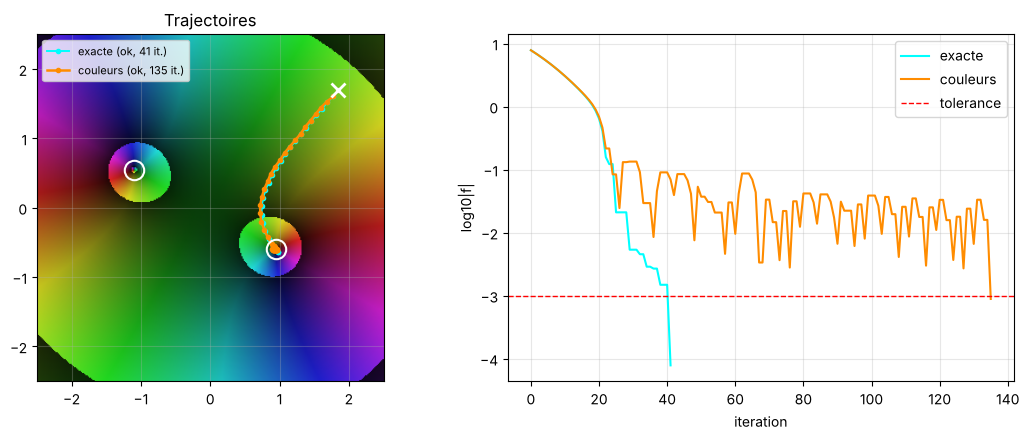

In [5]:
def descend(sensor, z0, alpha=0.12, eps=0.06, maxit=200, tol_log=-3.0,
            alpha_min=1e-4, eps_min=0.0):
    """Descente par couleurs : le capteur est la seule source d'information.

    Pas normalise avec backtracking sur la luminosite decodee : si la couleur
    indique que log|f| n'a pas diminue, le pas est divise par 2 (et eps suit le pas).
    Sans cela, un pas fixe oscille a distance ~alpha du zero et n'atteint jamais la tolerance.
    """
    f = sensor.f

    def true_log(z):  # oracle (mesure uniquement, pas utilise pour avancer)
        return np.log10(max(abs(f(np.asarray(z, dtype=complex))), 1e-300))

    z = z0
    traj, logs, status = [z], [true_log(z)], "max"
    last = decode_t(sensor.read(z))
    step = alpha
    margin = 1.5 / (LAMP * (2 ** min(getattr(sensor, 'bits', 8), 12) - 1))  # tolerance au bruit de quantification
    for _ in range(maxit):
        e = max(eps_min, min(eps, 2 * step))
        t0 = decode_t(sensor.read(z), last)
        tE = decode_t(sensor.read(z + e), t0)
        tW = decode_t(sensor.read(z - e), t0)
        tN = decode_t(sensor.read(z + 1j * e), t0)
        tS = decode_t(sensor.read(z - 1j * e), t0)
        last = t0
        gx, gy = (tE - tW) / (2 * e), (tN - tS) / (2 * e)
        gn = math.hypot(gx, gy)
        if gn < 1e-8:
            status = "stall"
            break
        cand = z - step * (gx + 1j * gy) / gn
        if decode_t(sensor.read(cand), t0) > t0 + margin:   # la couleur dit "plus haut" -> pas trop grand
            step /= 2
            if step < alpha_min:
                status = "stall"
                break
            traj.append(z)
            logs.append(logs[-1])
            continue
        z = cand
        step = min(alpha, step * 1.5)
        traj.append(z)
        logs.append(true_log(z))
        if logs[-1] < tol_log:
            status = "ok"
            break
    return np.array(traj), np.array(logs), status


def descend_exact(f, z0, alpha=0.12, maxit=200, tol_log=-3.0, alpha_min=1e-4):
    """Descente exacte : direction conj(f'/f), gradient de log|f| (f analytique), meme backtracking."""
    h = 1e-7

    def true_log(z):
        return np.log10(max(abs(f(np.asarray(z, dtype=complex))), 1e-300))

    def df(z):
        return (f(np.asarray(z, dtype=complex) + h) - f(np.asarray(z, dtype=complex) - h)) / (2 * h)

    z = z0
    traj, logs, status = [z], [true_log(z)], "max"
    step = alpha
    for _ in range(maxit):
        w = df(z) / f(np.asarray(z, dtype=complex))
        gn = abs(w)
        if gn < 1e-14:
            status = "stall"
            break
        cand = z - step * np.conj(w) / gn
        lc = true_log(cand)
        if lc > logs[-1]:
            step /= 2
            if step < alpha_min:
                status = "stall"
                break
            traj.append(z)
            logs.append(logs[-1])
            continue
        z = cand
        step = min(alpha, step * 1.5)
        traj.append(z)
        logs.append(lc)
        if lc < tol_log:
            status = "ok"
            break
    return np.array(traj), np.array(logs), status


# -- demonstration sur 'quad' --
cfg = TESTS["quad"]
sens = ImageSensor(cfg["f"], cfg["xlim"], cfg["ylim"], N=300)
z0 = 1.85 + 1.70j
traj_c, logs_c, st_c = descend(sens, z0)
traj_e, logs_e, st_e = descend_exact(cfg["f"], z0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
sens.show(ax1)
ax1.plot(traj_e.real, traj_e.imag, "-o", c="cyan", ms=3, lw=1.4, label=f"exacte ({st_e}, {len(traj_e)-1} it.)")
ax1.plot(traj_c.real, traj_c.imag, "-o", c="darkorange", ms=3, lw=1.8, label=f"couleurs ({st_c}, {len(traj_c)-1} it.)")
for rz in cfg["zeros"]:
    ax1.plot(rz.real, rz.imag, "wo", mfc="none", ms=14, mew=1.5)
ax1.plot(z0.real, z0.imag, "wx", ms=10, mew=2)
ax1.legend(loc="upper left", fontsize=8)
ax1.set_title("Trajectoires")
ax2.plot(logs_e, c="cyan", label="exacte")
ax2.plot(logs_c, c="darkorange", label="couleurs")
ax2.axhline(-3.0, ls="--", c="r", lw=1, label="tolerance")
ax2.set_xlabel("iteration")
ax2.set_ylabel("log10|f|")
ax2.legend()
plt.tight_layout()
plt.show()


## 5. Protocole de benchmark

**Metriques** (agregees sur une grille de 4x4 = 16 points de depart) :

- **taux de succes** : fraction des departs qui atteignent `log_10|f| < tol` en <= maxit iterations
- **iterations moyennes** (sur les succes) - vitesse de convergence
- **distance moyenne au zero le plus proche** - precision de la solution
- **evaluations de f** - cout reel en appels a la fonction
- **temps moyen par descente** (ms)

Les tests T1-T6 font varier un parametre a la fois et alimentent un tableau
recapitulatif global (`RESULTS`) affiche et exporte en CSV a la fin.


In [6]:
def counted(f):
    """Enveloppe comptant les evaluations de f (scalaires ou tableaux)."""
    def g(z):
        g.n_evals += int(np.size(z))
        return f(z)
    g.n_evals = 0
    return g


def nearest_dist(z, zeros):
    if not zeros:
        return float("nan")
    return float(min(abs(z - r) for r in zeros))


def make_starts(cfg, n=4, margin=0.12):
    """Grille de n x n points de depart interieurs (marge de 12 %)."""
    xs = np.linspace(cfg["xlim"][0] + margin * (cfg["xlim"][1] - cfg["xlim"][0]),
                     cfg["xlim"][1] - margin * (cfg["xlim"][1] - cfg["xlim"][0]), n)
    ys = np.linspace(cfg["ylim"][0] + margin * (cfg["ylim"][1] - cfg["ylim"][0]),
                     cfg["ylim"][1] - margin * (cfg["ylim"][1] - cfg["ylim"][0]), n)
    return [x + 1j * y for x in xs for y in ys]


def run_suite(name, method="couleur", sensor="ondemand", starts=None, sensor_kw=None, **kw):
    """Lance la descente depuis chaque point de depart -> liste de resultats detailles."""
    cfg = TESTS[name]
    params = dict(alpha=0.12, eps=0.06, maxit=200, tol_log=-3.0)
    params.update(kw)   # les parametres balayes (eps, alpha, maxit, tol_log) remplacent les defauts
    starts = make_starts(cfg) if starts is None else starts
    skw = sensor_kw or {}

    sens_img = None
    if method == "couleur" and sensor == "image":
        sens_img = ImageSensor(cfg["f"], cfg["xlim"], cfg["ylim"], **skw)

    rows = []
    for z0 in starts:
        t0 = time.perf_counter()
        if method == "exact":
            fc = counted(cfg["f"])
            p = {k: v for k, v in params.items() if k not in ("eps", "eps_min")}
            traj, logs, status = descend_exact(fc, z0, **p)
            evals = fc.n_evals
        elif sensor == "image":
            traj, logs, status = descend(sens_img, z0, **params)
            evals = 0  # l'image absorbe le cout de rendu (N^2 evaluations, une seule fois)
        else:
            fc = counted(cfg["f"])
            sens = OnDemandSensor(fc, **skw)
            traj, logs, status = descend(sens, z0, **params)
            evals = fc.n_evals
        rows.append(dict(z0=z0, status=status, iters=len(logs) - 1, final_log=logs[-1],
                         dist=nearest_dist(traj[-1], cfg["zeros"]),
                         evals=evals, time=time.perf_counter() - t0))
    return rows


def summarize(rows, fn):
    ok = [r for r in rows if r["status"] == "ok"]
    return dict(fn=fn, n=len(rows), taux=len(ok) / len(rows),
                iters_moy=float(np.mean([r["iters"] for r in ok])) if ok else float("nan"),
                dist_moy=float(np.mean([r["dist"] for r in ok])) if ok else float("nan"),
                evals_moy=float(np.mean([r["evals"] for r in rows])),
                temps_moy=1e3 * float(np.mean([r["time"] for r in rows])))


RESULTS = []   # tableau recapitulatif global
print("Harness pret.")

Harness pret.


## T1 - Sensibilite a la distance d'echantillonnage eps

On balaye eps dans {0.01 ... 0.35} sur `quad`, pour les deux capteurs, avec une tolerance
`log_10|f| < -1.5` (un capteur image ne peut pas descendre sous la taille d'un pixel).

**Hypotheses :**
- capteur **image** : eps plus petit qu'un pixel (~ 0.017 ici) -> tous les echantillons dans le meme
  pixel -> gradient nul -> echec ;
- eps grand : les voisins tombent dans des **bandes de module differentes** -> erreurs de depliage ->
  mauvaises directions ;
- le capteur **a la demande** devrait etre robuste aux petits eps (pas d'aliasing spatial).


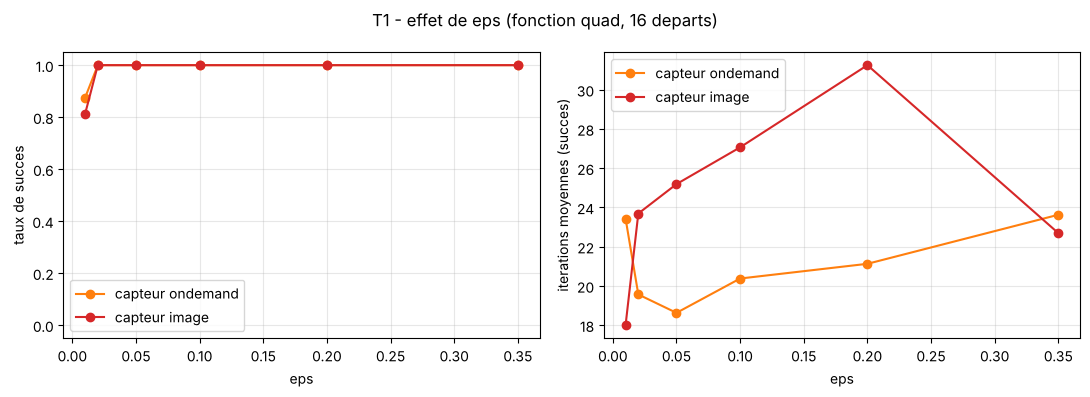

In [7]:
eps_list = [0.01, 0.02, 0.05, 0.10, 0.20, 0.35]
t1 = {}
for sensor in ["ondemand", "image"]:
    taux, iters = [], []
    for e in eps_list:
        rows = run_suite("quad", sensor=sensor, eps=e, tol_log=-1.5)
        row = summarize(rows, "quad")
        row.update(test="T1", capteur=sensor, eps=e)
        RESULTS.append(row)
        taux.append(row["taux"])
        iters.append(row["iters_moy"])
    t1[sensor] = (taux, iters)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for sensor, c in [("ondemand", "tab:orange"), ("image", "tab:red")]:
    taux, iters = t1[sensor]
    axes[0].plot(eps_list, taux, "o-", c=c, label=f"capteur {sensor}")
    axes[1].plot(eps_list, iters, "o-", c=c, label=f"capteur {sensor}")
axes[0].set_xlabel("eps") ; axes[0].set_ylabel("taux de succes") ; axes[0].set_ylim(-0.05, 1.05)
axes[1].set_xlabel("eps") ; axes[1].set_ylabel("iterations moyennes (succes)")
for ax in axes:
    ax.legend()
fig.suptitle("T1 - effet de eps (fonction quad, 16 departs)")
plt.tight_layout()
plt.show()


## T2 - Sensibilite au pas alpha

Balayage de alpha dans {0.02 ... 0.40} sur `quad` et `cubic` (capteur a la demande, eps = 0.06).

**Hypotheses :** alpha trop petit -> on n'atteint pas la tolerance en 200 iterations ;
alpha grand -> oscillations autour du zero (le pas est normalise, pas de divergence possible).


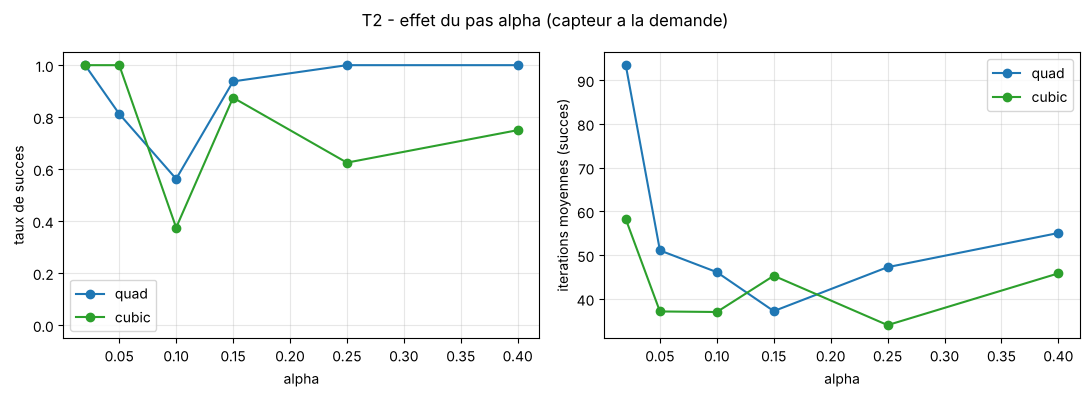

In [8]:
alpha_list = [0.02, 0.05, 0.10, 0.15, 0.25, 0.40]
t2 = {}
for fn in ["quad", "cubic"]:
    taux, iters = [], []
    for a in alpha_list:
        rows = run_suite(fn, alpha=a)
        row = summarize(rows, fn)
        row.update(test="T2", fn=fn, alpha=a)
        RESULTS.append(row)
        taux.append(row["taux"])
        iters.append(row["iters_moy"])
    t2[fn] = (taux, iters)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for fn, c in [("quad", "tab:blue"), ("cubic", "tab:green")]:
    taux, iters = t2[fn]
    axes[0].plot(alpha_list, taux, "o-", c=c, label=fn)
    axes[1].plot(alpha_list, iters, "o-", c=c, label=fn)
axes[0].set_xlabel("alpha") ; axes[0].set_ylabel("taux de succes") ; axes[0].set_ylim(-0.05, 1.05)
axes[1].set_xlabel("alpha") ; axes[1].set_ylabel("iterations moyennes (succes)")
for ax in axes:
    ax.legend()
fig.suptitle("T2 - effet du pas alpha (capteur a la demande)")
plt.tight_layout()
plt.show()


## T3 - Profondeur du capteur : la quantification en bits

Balayage de la profondeur : bits dans {2 ... 16}, capteur a la demande.
On mesure aussi l'**erreur d'angle** du gradient estime : l'angle entre le gradient
" couleur " et le gradient exact de `log|f|` (= `conj(f'/f)`) en 5 points sondes.

**Hypotheses :** 8 bits suffisent largement ; en dessous de ~4 bits le gradient
devient tres bruite (la bande est resolue sur 2^bits niveaux) -> echecs.


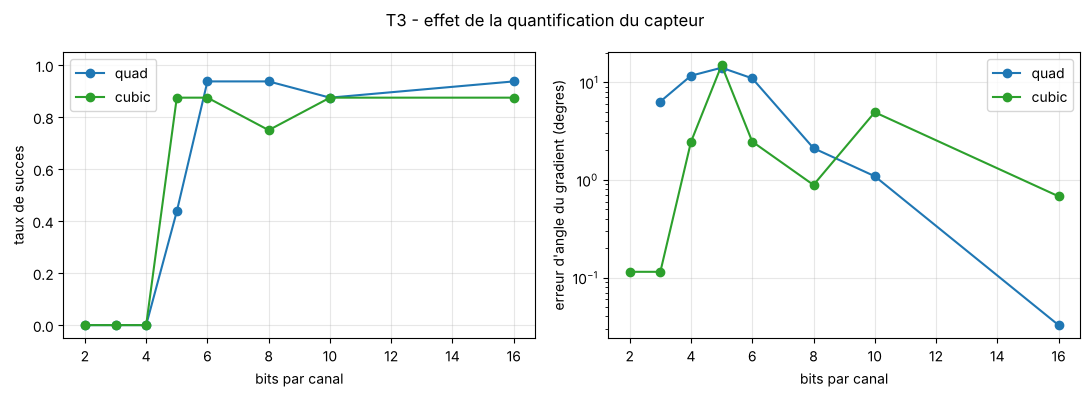

In [9]:
def gradient_angle_error(fn, z0, bits, eps=0.06):
    cfg = TESTS[fn]
    f = cfg["f"]
    sens = OnDemandSensor(f, bits=bits)
    t0 = decode_t(sens.read(z0))
    tE = decode_t(sens.read(z0 + eps), t0)
    tW = decode_t(sens.read(z0 - eps), t0)
    tN = decode_t(sens.read(z0 + 1j * eps), t0)
    tS = decode_t(sens.read(z0 - 1j * eps), t0)
    g_est = np.array([(tE - tW) / (2 * eps), (tN - tS) / (2 * eps)])
    if np.linalg.norm(g_est) < 1e-9:
        return float("nan")
    h = 1e-7
    w = (f(np.asarray(z0 + h)) - f(np.asarray(z0 - h))) / (2 * h) / f(np.asarray(z0))
    g_true = np.array([w.real, -w.imag])
    if np.linalg.norm(g_true) < 1e-14:
        return float("nan")
    cos = float(np.dot(g_est, g_true) / (np.linalg.norm(g_est) * np.linalg.norm(g_true)))
    return float(np.degrees(np.arccos(np.clip(cos, -1.0, 1.0))))


bits_list = [2, 3, 4, 5, 6, 8, 10, 16]
sondes = [-2 + 2j, 2 - 1.5j, -1.5 - 2j, 2.2 + 2j, 0.1 + 0.1j]
t3 = {}
for fn in ["quad", "cubic"]:
    taux, ang = [], []
    for b in bits_list:
        rows = run_suite(fn, sensor="ondemand", sensor_kw=dict(bits=b))
        row = summarize(rows, fn)
        row.update(test="T3", fn=fn, bits=b)
        RESULTS.append(row)
        taux.append(row["taux"])
        vals = [gradient_angle_error(fn, z0, b) for z0 in sondes]
        ang.append(float(np.nanmean(vals)) if not np.all(np.isnan(vals)) else float("nan"))
    t3[fn] = (taux, ang)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for fn, c in [("quad", "tab:blue"), ("cubic", "tab:green")]:
    taux, ang = t3[fn]
    axes[0].plot(bits_list, taux, "o-", c=c, label=fn)
    axes[1].semilogy(bits_list, np.maximum(ang, 1e-2), "o-", c=c, label=fn)
axes[0].set_xlabel("bits par canal") ; axes[0].set_ylabel("taux de succes") ; axes[0].set_ylim(-0.05, 1.05)
axes[1].set_xlabel("bits par canal") ; axes[1].set_ylabel("erreur d'angle du gradient (degres)")
for ax in axes:
    ax.legend()
fig.suptitle("T3 - effet de la quantification du capteur")
plt.tight_layout()
plt.show()


## T4 - Resolution de l'image (aliasing du capteur image)

Balayage de N dans {64 ... 512} pixels pour le capteur image, sur `poly5`.
Tolerance `log_10|f| < -1.5` (limite de precision d'une image). Rappel : pixel = fenetre / N ~ 5/N unites du plan. Avec eps = 0.06, il faut
pixel < eps ~ 0.06, soit N >~ 80, pour que les 4 voisins soient distincts.

**Hypotheses :** taux de succes qui s'effondre a basse resolution (echantillons
dans le meme pixel), et distance finale limitee par l'aliasing quand ca reussit.


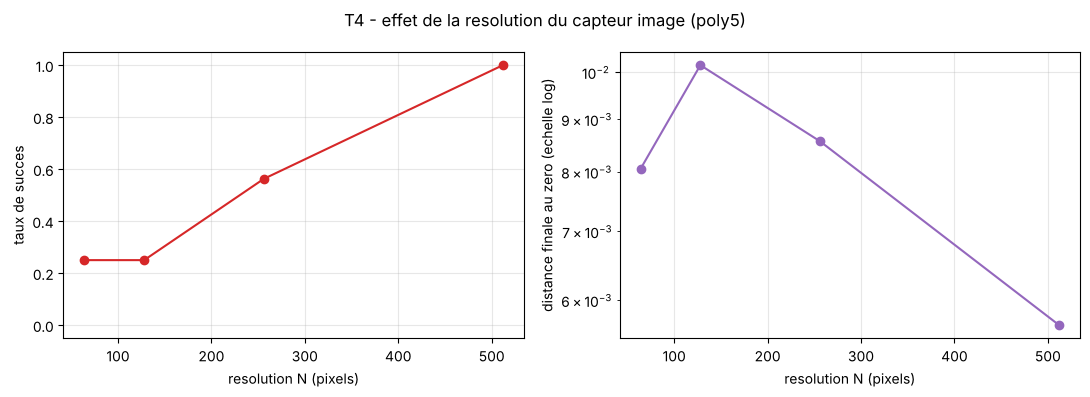

In [10]:
N_list = [64, 128, 256, 512]
taux4, iters4, dist4 = [], [], []
for Npix in N_list:
    rows = run_suite("poly5", sensor="image", sensor_kw=dict(N=Npix), tol_log=-1.5, eps_min=0.0)
    row = summarize(rows, "poly5")
    row.update(test="T4", fn="poly5", N=Npix, capteur="image",
               note=f"rendu = {Npix**2} evaluations de f (une fois)")
    RESULTS.append(row)
    taux4.append(row["taux"])
    iters4.append(row["iters_moy"])
    dist4.append(row["dist_moy"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(N_list, taux4, "o-", c="tab:red")
axes[0].set_xlabel("resolution N (pixels)") ; axes[0].set_ylabel("taux de succes") ; axes[0].set_ylim(-0.05, 1.05)
axes[1].semilogy(N_list, np.maximum(dist4, 1e-4), "o-", c="tab:purple")
axes[1].set_xlabel("resolution N (pixels)") ; axes[1].set_ylabel("distance finale au zero (echelle log)")
fig.suptitle("T4 - effet de la resolution du capteur image (poly5)")
plt.tight_layout()
plt.show()


## T5 - Cout reel : evaluations de f et temps

Comparaison descente **par couleurs** (capteur a la demande) vs **exacte**,
sur les 6 fonctions. Comptage exact des evaluations de f par descente.

**Ce qu'on attend :** des couts du meme ordre (~6-7 evaluations par iteration) -
l'encodage couleur ne fait pas economiser d'evaluations quand f est disponible ;
son interet est l'**invariance d'echelle** et le scenario capteur quantifie,
pas l'efficacite brute. Note : en mode image, la descente coute 0 evaluation
(parcontre le rendu initial en coute N^2, une seule fois).


,fn,methode,taux,iters_moy,dist_moy,evals_moy,temps_moy
0,quad,couleurs,0.938,43.400,0.000,291.062,40.650
1,quad,exacte,1.000,26.875,0.000,108.500,0.439
2,cubic,couleurs,0.750,37.333,0.000,262.250,34.772
3,cubic,exacte,1.000,21.375,0.000,86.500,0.399
4,expz,couleurs,1.000,58.375,NaN,402.625,53.221
5,expz,exacte,1.000,48.250,NaN,194.000,1.361
6,poly5,couleurs,0.750,48.333,0.000,393.625,65.437
7,poly5,exacte,0.875,30.143,0.000,127.250,1.859
8,double,couleurs,1.000,33.062,0.011,224.625,29.899
9,double,exacte,1.000,20.125,0.006,81.500,0.361


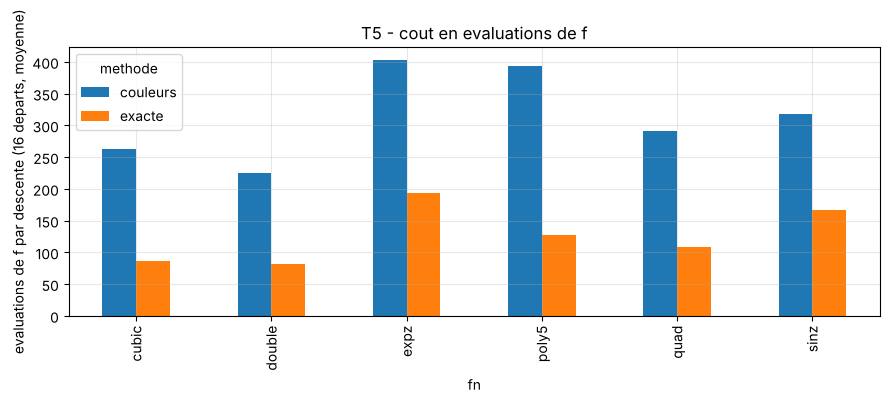

In [11]:
comp = []
for fn in TESTS:
    rows_c = run_suite(fn, sensor="ondemand")
    row_c = summarize(rows_c, fn) ; row_c.update(test="T5", methode="couleurs", fn=fn)
    rows_e = run_suite(fn, method="exact")
    row_e = summarize(rows_e, fn) ; row_e.update(test="T5", methode="exacte", fn=fn)
    RESULTS += [row_c, row_e]
    comp += [row_c, row_e]

df5 = pd.DataFrame(comp)[["fn", "methode", "taux", "iters_moy", "dist_moy", "evals_moy", "temps_moy"]]
display(df5.round(3))

ax = df5.pivot(index="fn", columns="methode", values="evals_moy").plot.bar(figsize=(9, 4))
ax.set_ylabel("evaluations de f par descente (16 departs, moyenne)")
ax.set_title("T5 - cout en evaluations de f")
plt.tight_layout()
plt.show()


## T6 - Robustesse : racines multiples + tableau recapitulatif

Test des racines multiples (`double` : racine double, `sinz` : racine triple) avec
une tolerance plus severe (`log_10|f| < -4`) et 400 iterations max.
La descente sur `log|f|` reste bien conditionnee pour les racines multiples
(le gradient de `log|f|` ne depend pas de la multiplicite), contrairement a Newton.

Puis : **tableau recapitulatif global** de tous les tests, exporte en CSV.


In [12]:
mult = []
for fn in ["quad", "double", "sinz"]:
    rows = run_suite(fn, sensor="ondemand", maxit=400, tol_log=-4.0)
    row = summarize(rows, fn)
    row.update(test="T6-multiplicite", fn=fn)
    RESULTS.append(row)
    mult.append(row)

display(pd.DataFrame(mult)[["fn", "taux", "iters_moy", "dist_moy"]].round(3))

df_all = pd.DataFrame(RESULTS)
cols = [c for c in ["test", "fn", "capteur", "methode", "eps", "alpha", "bits", "N",
                    "n", "taux", "iters_moy", "dist_moy", "evals_moy", "temps_moy"]
        if c in df_all.columns]
display(df_all[cols].round(3))
df_all.to_csv("benchmark_descente_couleurs.csv", index=False)
print("Resultats exportes : benchmark_descente_couleurs.csv")


,fn,taux,iters_moy,dist_moy
0,quad,0.625,49.600,0.000
1,double,0.875,41.357,0.005
2,sinz,1.000,56.250,0.077


,test,fn,capteur,methode,eps,alpha,bits,N,n,taux,iters_moy,dist_moy,evals_moy,temps_moy
0,T1,quad,ondemand,NaN,0.01,NaN,NaN,NaN,16,0.875,23.429,0.005,142.625,21.749
1,T1,quad,ondemand,NaN,0.02,NaN,NaN,NaN,16,1.000,19.562,0.007,136.000,18.074
2,T1,quad,ondemand,NaN,0.05,NaN,NaN,NaN,16,1.000,18.625,0.007,129.625,17.163
3,T1,quad,ondemand,NaN,0.10,NaN,NaN,NaN,16,1.000,20.375,0.007,140.875,17.347
4,T1,quad,ondemand,NaN,0.20,NaN,NaN,NaN,16,1.000,21.125,0.009,145.125,17.732
5,T1,quad,ondemand,NaN,0.35,NaN,NaN,NaN,16,1.000,23.625,0.006,161.438,20.295
6,T1,quad,image,NaN,0.01,NaN,NaN,NaN,16,0.812,18.000,0.009,0.000,3.508
7,T1,quad,image,NaN,0.02,NaN,NaN,NaN,16,1.000,23.688,0.008,0.000,5.303
8,T1,quad,image,NaN,0.05,NaN,NaN,NaN,16,1.000,25.188,0.007,0.000,5.595
9,T1,quad,image,NaN,0.10,NaN,NaN,NaN,16,1.000,27.062,0.008,0.000,5.895


Resultats exportes : benchmark_descente_couleurs.csv


## Bilan

**Lecture attendue des resultats**

- **T1** : il existe une *fenetre* de eps viable - trop petit, le capteur image ne voit plus
  de difference (gradient nul) ; trop grand, le depliage de bande se trompe. Le capteur a la
  demande est robuste aux petits eps : c'est le mode a privilegier.
- **T2** : le pas normalise rend la methode tres stable (pas de divergence), au prix d'une
  convergence lineaire en alpha (max ~ alpha par iteration) ; le backtracking evite les
  oscillations autour du zero.
- **T3** : ~5-6 bits par canal sont necessaires pour converger (0 % de succes a 4 bits ou moins) ; 8 bits (image standard) donnent
  une erreur d'angle du gradient de l'ordre de quelques degres - largement assez pour une
  descente normalisee.
- **T4** : l'aliasing du capteur image est le facteur limitant reel : il faut des pixels
  plus fins que eps, et la precision finale reste bornee par la resolution.
- **T5** : aucune economie d'evaluations quand f est disponible - l'interet du capteur
  couleur est ailleurs : invariance d'echelle (le log gere une dynamique de 10^+/-300),
  et validite quand la seule donnee est une image ou un capteur quantifie.
- **T6** : les racines multiples ne posent pas de probleme (taux de succes comparable aux racines simples ; avec tol = -4 la quantification 8 bits limite certains departs) - mais pas de gain face a Newton :
  sur une racine multiple Newton perd sa convergence quadratique (elle devient lineaire) sans diverger, et reste plus rapide
  que la descente (voir `extensions_descente_par_couleurs.ipynb`, experience 3).

**Note** : les taux de succes ne sont pas toujours monotones (departs sur les crêtes entre bassins, bruit de quantification) ; lire les tendances plutot que les valeurs exactes.

**Ce que ce benchmark ne teste pas** : convergence globale (multi-departs, bassins),
dimensions > 2, bruit du capteur reel, fonctions non analytiques.

**Pour aller plus loin**
- Remplacer le backtracking simple par un line search plus fin sur la luminosite decodee ;
- Exploiter la **teinte** (l'enroulement de `arg f` = indice, principe de l'argument) pour
  un Newton colorimetrique : Delves & Lyness (1967), *A numerical method for locating the
  zeros of an analytic function* ;
- Comparer aux methodes a gradient quantifie : signSGD (Bernstein et al., 2018),
  QSGD (Alistarh et al., 2017) - meme problematique d'estimer une direction avec
  une information grossiere.